# Taller 2 – MINE-4101 Ciencia de Datos Aplicada
## Predicción de abandono (churn) de clientes – FinAlpes

**Integrantes:** Jorge Acosta (202324675) · Mateo Bonil (código)

**Cómo ejecutar:** abrir en Google Colab o Jupyter, dejar `churn.csv` en la misma carpeta que este notebook y ejecutar **todas las celdas en orden** (menú *Ejecutar todo / Run all*).

**Contenido**
1. Entendimiento y preparación de los datos (10%)
2. Entrenamiento de modelos (15%)
3. Análisis cuantitativo (20%)
4. Análisis cualitativo / interpretabilidad (20%)
5. Generación de valor (20%)
6. Insights y recomendación (10%) → ver también el informe ejecutivo
7. Declaración de uso de IA generativa (5%)

> Las celdas marcadas con ✍️ son para que ustedes escriban su análisis con sus propias palabras.

### 0. Instalación y librerías

In [1]:
# Solo hace falta la primera vez (en Colab sí es necesario). Instala SHAP y LIME, usados en la sección 4.
%pip install shap lime -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             classification_report)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

SEMILLA = 42                      # fija la aleatoriedad para que los resultados sean reproducibles
np.random.seed(SEMILLA)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

---
## 1. Entendimiento y preparación de los datos (10%)
### 1.1 Carga y vista general

In [3]:
df_raw = pd.read_csv("churn.csv")
print("Dimensiones (filas, columnas):", df_raw.shape)
df_raw.head()

Dimensiones (filas, columnas): (10045, 11)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.000,France,Female,46.000,9,0.000,1,1,1,"81,014.500",1
1,689.000,Germany,Male,67.000,9,"157,094.780",1,1,1,"99,490.010",0
2,477.000,Spain,Female,48.000,2,"129,120.640",1,0,1,"26,475.790",0
3,573.000,Germany,Female,35.000,9,"206,868.780",2,0,1,"102,986.150",0
4,849.000,France,Male,69.000,7,"71,996.090",1,1,1,"139,065.940",0


In [4]:
# Tipo de cada variable y conteo de valores no nulos
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  object 
 2   gender            10045 non-null  object 
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 863.4+ KB


**Diccionario de variables** (completar/validar):

| Variable | Tipo | Descripción |
|---|---|---|
| credit_score | numérica | Puntaje crediticio del cliente |
| country | categórica | País (France, Germany, Spain) |
| gender | categórica | Género |
| age | numérica | Edad |
| tenure | numérica discreta | Años como cliente |
| balance | numérica | Saldo en cuenta |
| products_number | numérica discreta | Número de productos contratados |
| credit_card | binaria | Tiene tarjeta de crédito (1/0) |
| active_member | binaria | Es miembro activo (1/0) |
| estimated_salary | numérica | Salario estimado |
| **churn** | **binaria (objetivo)** | 1 = el cliente abandonó |

### 1.2 Calidad de datos: nulos, duplicados, categorías y valores imposibles

In [5]:
calidad = pd.DataFrame({
    "nulos": df_raw.isna().sum(),
    "% nulos": (df_raw.isna().mean() * 100).round(2),
    "valores únicos": df_raw.nunique(),
})
print("Filas duplicadas:", df_raw.duplicated().sum())
calidad

Filas duplicadas: 45


,nulos,% nulos,valores únicos
credit_score,250,2.490,461
country,0,0.000,9
gender,0,0.000,4
age,300,2.990,76
tenure,0,0.000,14
balance,200,1.990,6240
products_number,0,0.000,4
credit_card,0,0.000,2
active_member,0,0.000,2
estimated_salary,350,3.480,9649


In [6]:
# Las variables de texto tienen la misma categoría escrita de varias formas
for col in ["country", "gender"]:
    print(df_raw[col].value_counts(dropna=False), "\n")

country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64 

gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64 



In [7]:
# Estadísticas descriptivas: fíjense en mínimos y máximos imposibles (edad -1 o 210, salario negativo...)
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
credit_score,"9,795.000",650.690,97.088,95.000,584.000,652.000,718.000,"1,200.000"
age,"9,745.000",38.938,10.734,-1.000,32.000,37.000,44.000,210.000
tenure,"10,045.000",5.019,2.902,-2.000,3.000,5.000,8.000,25.000
balance,"9,845.000","76,317.500","62,422.435",0.000,0.000,"97,042.600","127,559.970","250,898.090"
products_number,"10,045.000",1.530,0.582,1.000,1.000,1.000,2.000,4.000
credit_card,"10,045.000",0.705,0.456,0.000,0.000,1.000,1.000,1.000
active_member,"10,045.000",0.515,0.500,0.000,0.000,1.000,1.000,1.000
estimated_salary,"9,695.000","100,069.015","57,510.689","-5,000.000","51,013.655","100,130.950","149,382.875","199,992.480"
churn,"10,045.000",0.204,0.403,0.000,0.000,0.000,0.000,1.000


### 1.3 Limpieza
Reglas aplicadas (cada una se justifica por conocimiento del negocio):

1. **Categorías inconsistentes**: `FRANCE`, `france` → `France`; `M` → `Male`, `F` → `Female`.
2. **Duplicados**: se eliminan las filas exactamente repetidas.
3. **Valores imposibles → nulo** (luego se imputan con la mediana del entrenamiento):
   - `age` fuera de [18, 100]
   - `credit_score` fuera de [300, 850] (rango estándar del puntaje FICO)
   - `estimated_salary` < 0
   - tenure fuera de [0, 10] (-2, 15 y 25 son errores aislados)
4. **Nulos**: se imputan con la **mediana**, calculada *solo con el conjunto de entrenamiento* (dentro del pipeline) para evitar fuga de información (*data leakage*).

In [8]:
df = df_raw.copy()

# 1. Estandarizar texto
df["country"] = df["country"].str.strip().str.title()
df["gender"] = df["gender"].str.strip().replace({"M": "Male", "F": "Female"})

# 2. Eliminar duplicados
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {n_antes - len(df)}")

# 3. Valores imposibles -> NaN
reglas = {
    "age": ~df["age"].between(18, 100),
    "credit_score": ~df["credit_score"].between(300, 850),
    "estimated_salary": df["estimated_salary"] < 0,
"tenure": ~df["tenure"].between(0, 10),}
for col, mascara in reglas.items():
    mascara = mascara & df[col].notna()
    print(f"{col}: {mascara.sum()} valores imposibles convertidos a nulo")
    df.loc[mascara, col] = np.nan

print("\nDimensiones después de limpiar:", df.shape)
print(df["country"].value_counts(), "\n", df["gender"].value_counts())

Duplicados eliminados: 45
age: 6 valores imposibles convertidos a nulo
credit_score: 4 valores imposibles convertidos a nulo
estimated_salary: 3 valores imposibles convertidos a nulo
tenure: 3 valores imposibles convertidos a nulo

Dimensiones después de limpiar: (10000, 11)
country
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64 
 gender
Male      5457
Female    4543
Name: count, dtype: int64


### 1.4 Distribuciones e indicadores

Tasa de churn en el dataset: 20.4%  (2037 de 10000 clientes)


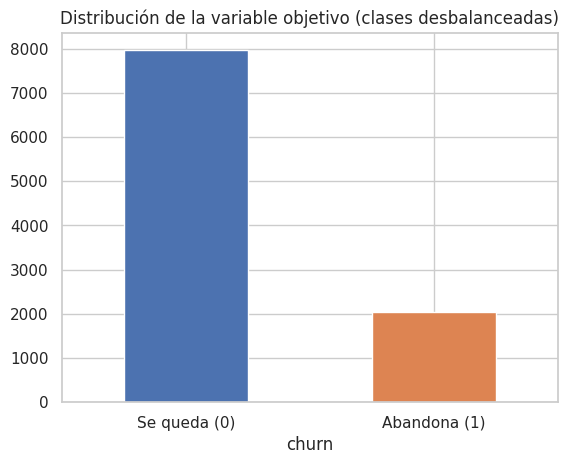

In [9]:
tasa = df["churn"].mean()
print(f"Tasa de churn en el dataset: {tasa:.1%}  ({df['churn'].sum()} de {len(df)} clientes)")
ax = df["churn"].value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_xticklabels(["Se queda (0)", "Abandona (1)"], rotation=0)
ax.set_title("Distribución de la variable objetivo (clases desbalanceadas)")
plt.show()

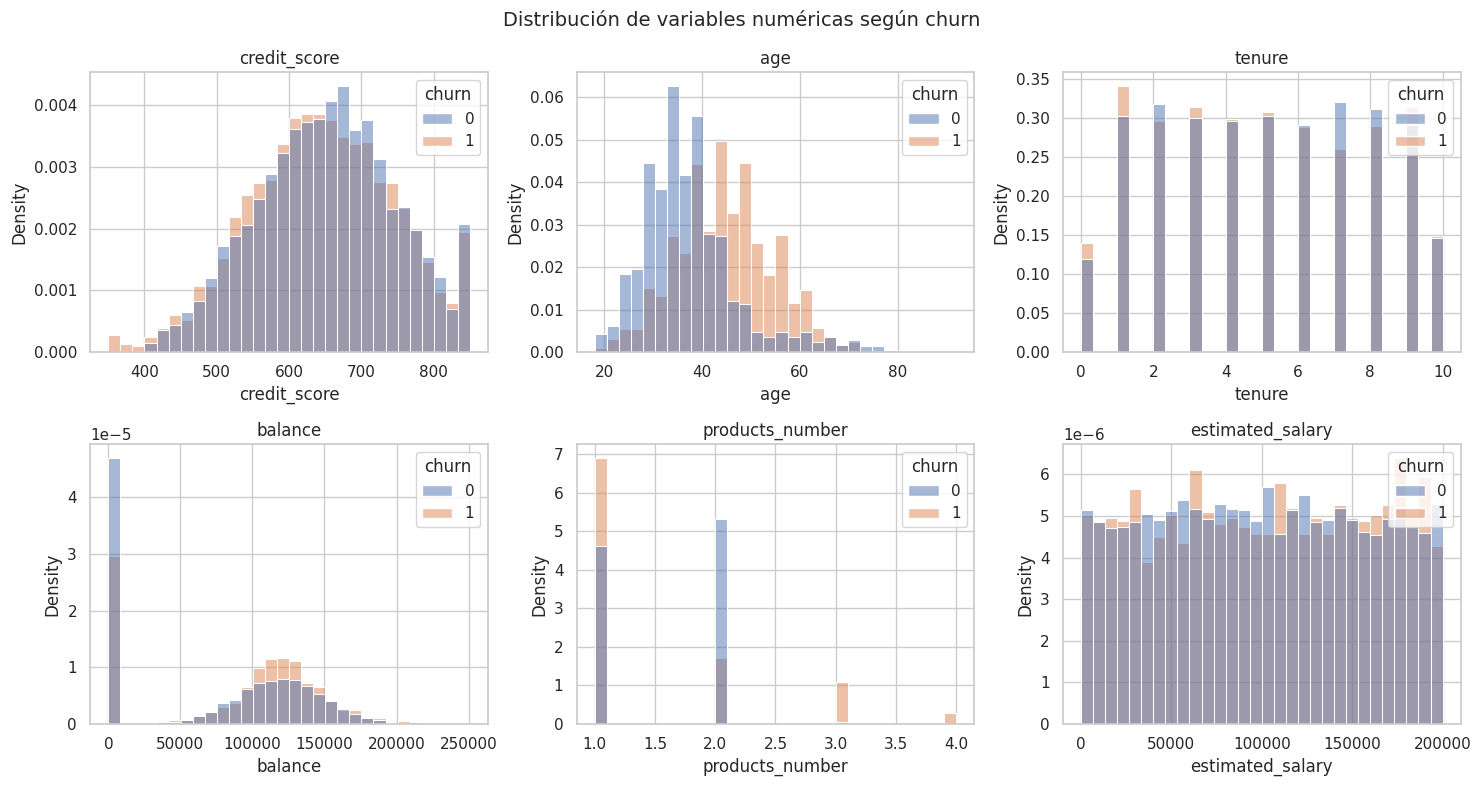

In [10]:
numericas = ["credit_score", "age", "tenure", "balance", "products_number", "estimated_salary"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numericas):
    sns.histplot(data=df, x=col, hue="churn", bins=30, ax=ax, stat="density", common_norm=False)
    ax.set_title(col)
plt.suptitle("Distribución de variables numéricas según churn", fontsize=14)
plt.tight_layout(); plt.show()

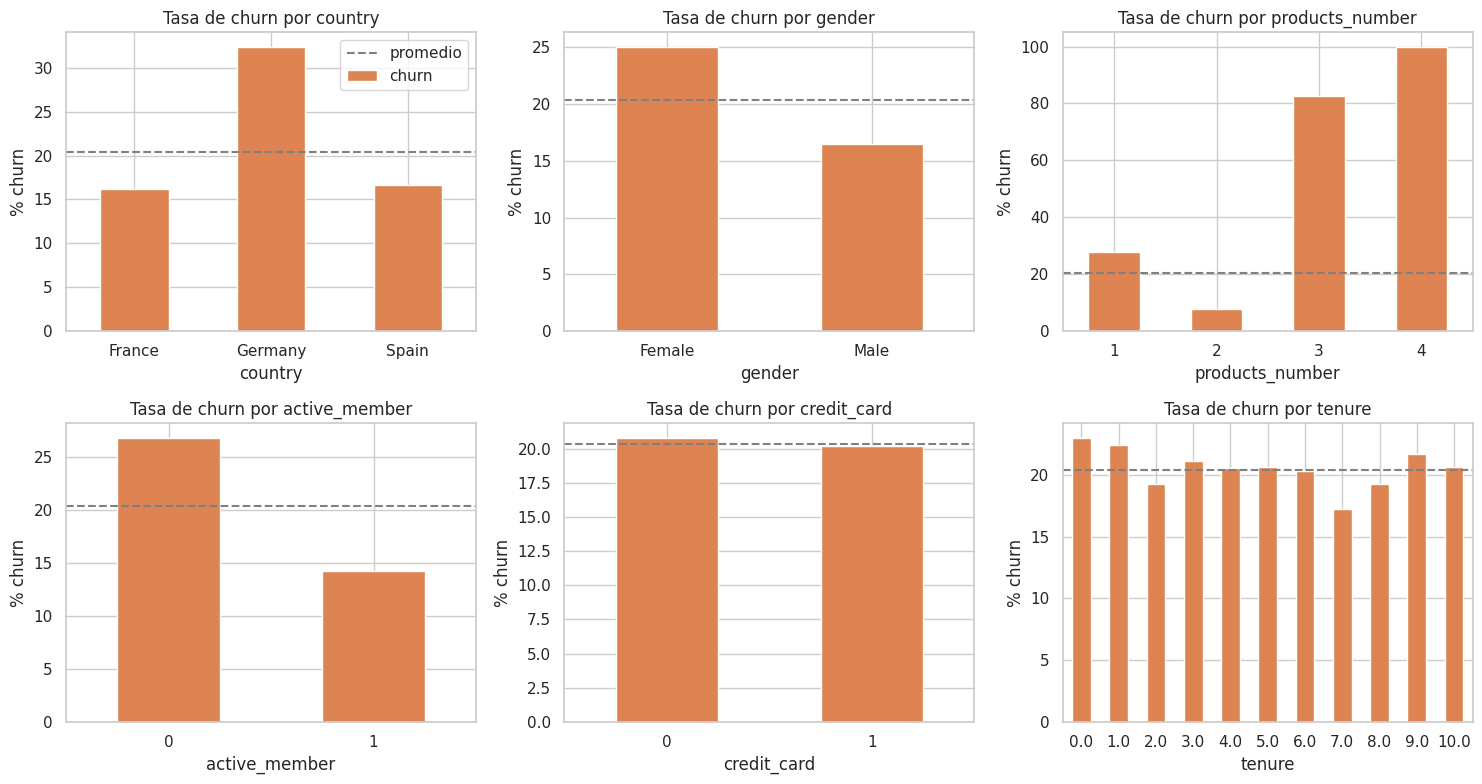

In [11]:
# Tasa de churn por cada categoría: ¿qué grupos abandonan más?
categoricas = ["country", "gender", "products_number", "active_member", "credit_card", "tenure"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), categoricas):
    (df.groupby(col)["churn"].mean() * 100).plot(kind="bar", ax=ax, color="#DD8452")
    ax.axhline(tasa * 100, ls="--", color="gray", label="promedio")
    ax.set_ylabel("% churn"); ax.set_title(f"Tasa de churn por {col}"); ax.tick_params(axis="x", rotation=0)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

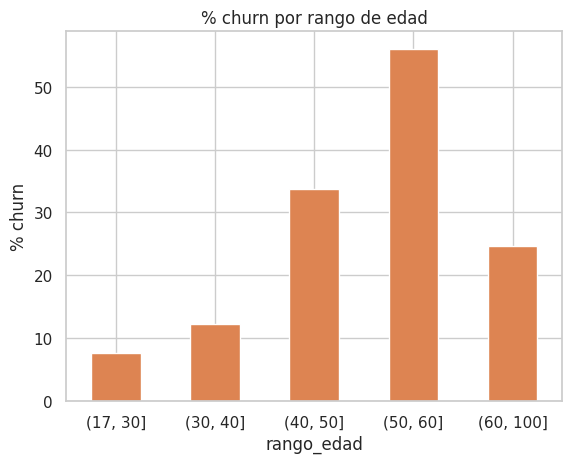

In [12]:
# Tasa de churn por rango de edad
df["rango_edad"] = pd.cut(df["age"], bins=[17, 30, 40, 50, 60, 100])
(df.groupby("rango_edad", observed=True)["churn"].mean() * 100).plot(kind="bar", color="#DD8452", title="% churn por rango de edad")
plt.ylabel("% churn"); plt.xticks(rotation=0); plt.show()
df = df.drop(columns="rango_edad")

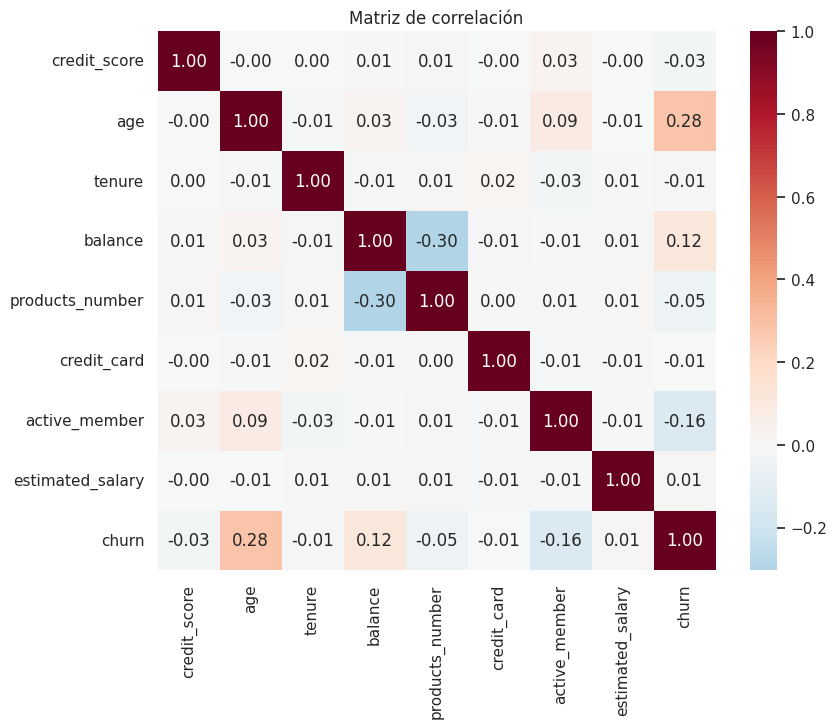

In [13]:
# Correlación entre variables numéricas y con el objetivo
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Matriz de correlación"); plt.show()

 **Conclusiones del entendimiento de datos**
- El conjunto inicial contiene 10.045 clientes y 11 variables: 6 numéricas, 2 categóricas (país y género) y 3 binarias (tarjeta de crédito, miembro activo y churn). Después de la limpieza quedan 10.000 clientes para el análisis.
- Calidad de los datos: se encontraron 45 registros duplicados, categorías escritas de diferentes formas, valores nulos entre 1,99% y 3,48% en cuatro variables y valores imposibles, como edades negativas o de 210 años, salarios negativos y antigüedades fuera del rango permitido. Esto demuestra que fue necesario depurar la información para evitar errores en las predicciones.
- El churn es del 20,4%, es decir, aproximadamente 20 de cada 100 clientes abandonan el banco. Las clases están desbalanceadas, por lo que la exactitud (accuracy) puede ser engañosa: un modelo que prediga que todos permanecen tendría cerca del 80% de aciertos, pero no identificaría a ningún cliente que se va.
- Los grupos con mayor abandono son los clientes de Alemania (32% frente a 16% en Francia y España), las mujeres (25% frente a 16% en hombres) y los clientes inactivos (27% frente a 14% en activos). Esto sugiere que el banco debe prestar especial atención a estos segmentos mediante estrategias de fidelización y reactivación.
- El número de productos presenta un comportamiento particular: los clientes con 2 productos tienen un churn cercano al 8%, mientras que con 3 productos aumenta al 83% y con 4 llega al 100%. Esto podría indicar que tener demasiados productos no necesariamente significa mayor satisfacción y que algunos clientes podrían estar experimentando dificultades o insatisfacción con los servicios contratados. Es importante validar estos grupos por su tamaño.

- La edad también es un factor relevante: el abandono aumenta especialmente a partir de los 40 años, lo que indica que los clientes de mayor edad requieren estrategias de atención y retención diferenciadas.

- Tener tarjeta de crédito y la antigüedad como cliente muestran diferencias pequeñas en las tasas de abandono, por lo que, individualmente, parecen tener menor capacidad para identificar clientes en riesgo.

---
## 2. Entrenamiento de modelos (15%)
### 2.1 Preparación de variables y división de datos
- `country` se convierte en variables *dummy* (one-hot) y `gender` en binaria.
- **División**: 80% entrenamiento / 20% prueba, **estratificada** (misma proporción de churn en ambos).
- El conjunto de **prueba no se toca** hasta la evaluación final. Los hiperparámetros se eligen con **validación cruzada de 5 particiones** sobre el entrenamiento.

In [14]:
X = df.drop(columns="churn").copy()
y = df["churn"]

X["gender"] = (X["gender"] == "Male").astype(int)              # 1 = hombre, 0 = mujer
X = pd.get_dummies(X, columns=["country"], drop_first=True, dtype=int)   # France es la categoría base
X = X.astype(float)                                              # todo numérico decimal (lo exigen algunas gráficas)
FEATURES = X.columns.tolist()
print("Variables del modelo:", FEATURES)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
print(f"Entrenamiento: {X_train.shape}, churn {y_train.mean():.1%}")
print(f"Prueba:        {X_test.shape}, churn {y_test.mean():.1%}")

Variables del modelo: ['credit_score', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'country_Germany', 'country_Spain']
Entrenamiento: (8000, 11), churn 20.4%
Prueba:        (2000, 11), churn 20.3%


### 2.2 Modelos y búsqueda de hiperparámetros
Se prueban tres modelos vistos en clase:

| Modelo | Por qué | Hiperparámetros buscados |
|---|---|---|
| Regresión logística | Línea base, interpretable (coeficientes) | `C` (regularización), `class_weight` |
| Random Forest | Ensamble de árboles, capta no linealidades | `n_estimators`, `max_depth`, `min_samples_leaf`, `class_weight` |
| Gradient Boosting | Ensamble secuencial, suele ser el más preciso en datos tabulares | `n_estimators`, `learning_rate`, `max_depth` |

- **Métrica de selección: ROC-AUC**, porque la clase está desbalanceada (la *accuracy* engaña: un modelo que dice "nadie se va" ya acierta ~80%).
- `class_weight="balanced"` le da más peso a los clientes que abandonan, para compensar el desbalance.
- Cada modelo es un **Pipeline** (imputación → [escalado] → modelo), así la mediana se calcula solo con los datos de entrenamiento de cada partición.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

modelos = {
    "Regresión logística": (
        Pipeline([("imputer", SimpleImputer(strategy="median")),
                  ("scaler", StandardScaler()),
                  ("model", LogisticRegression(max_iter=2000))]),
        {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
    "Random Forest": (
        Pipeline([("imputer", SimpleImputer(strategy="median")),
                  ("model", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1))]),
        {"model__n_estimators": [300], "model__max_depth": [6, 10, None],
         "model__min_samples_leaf": [1, 5, 10], "model__class_weight": [None, "balanced"]}),
    "Gradient Boosting": (
        Pipeline([("imputer", SimpleImputer(strategy="median")),
                  ("model", GradientBoostingClassifier(random_state=SEMILLA))]),
        {"model__n_estimators": [100, 300], "model__learning_rate": [0.05, 0.1],
         "model__max_depth": [2, 3, 4]}),
}

busquedas, resumen_cv = {}, []
for nombre, (pipe, grid) in modelos.items():
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    resumen_cv.append({"Modelo": nombre, "ROC-AUC CV (media)": gs.best_score_,
                       "Desv. estándar": gs.cv_results_["std_test_score"][gs.best_index_],
                       "Mejores hiperparámetros": gs.best_params_})
    print(f"✔ {nombre}: AUC CV = {gs.best_score_:.4f}")

resumen_cv = pd.DataFrame(resumen_cv).sort_values("ROC-AUC CV (media)", ascending=False)
pd.set_option("display.max_colwidth", None)
resumen_cv

✔ Regresión logística: AUC CV = 0.7615
✔ Random Forest: AUC CV = 0.8603
✔ Gradient Boosting: AUC CV = 0.8623


,Modelo,ROC-AUC CV (media),Desv. estándar,Mejores hiperparámetros
2,Gradient Boosting,0.862,0.011,"{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}"
1,Random Forest,0.860,0.009,"{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}"
0,Regresión logística,0.762,0.007,"{'model__C': 10, 'model__class_weight': 'balanced'}"


**Modelos y documentacion del entrenamiento**

1.   División de datos: se utilizaron 8.000 clientes (80%) para entrenamiento y 2.000 (20%) para prueba. La división fue estratificada para mantener una proporción similar de clientes que abandonan y permanecen, evitando distorsiones en la evaluación.
2. Ajuste de hiperparámetros: se utilizó GridSearch con validación cruzada de 5 particiones y ROC-AUC como métrica, porque permite evaluar qué tan bien el modelo diferencia entre clientes que abandonan y los que permanecen, sin depender de un umbral específico de clasificación.
3. Regresión logística: obtuvo un AUC de validación cruzada de 0,762, con C=10 y balanceo de clases. Es el modelo con menor capacidad predictiva de los tres evaluados.
4. Random Forest: obtuvo un AUC de 0,860, utilizando 300 árboles, profundidad máxima de 10, mínimo de 5 clientes por hoja y balanceo de clases. Presenta una mejora importante frente a la regresión logística.
5. Gradient Boosting: obtuvo el mejor resultado, con AUC de 0,862, utilizando 100 árboles, profundidad máxima de 3 y learning rate de 0,1. Esto demuestra una mayor capacidad para distinguir clientes con riesgo de abandono.
5. La desviación estándar entre las cinco particiones es cercana a 0,01 en los tres modelos, lo que indica que los resultados son relativamente estables y no dependen demasiado de una única división de los datos.
6. Los modelos basados en árboles superan claramente a la regresión logística porque pueden identificar relaciones no lineales e interacciones entre variables, como ocurre con la edad y el número de productos, cuyos efectos sobre el abandono no siguen un comportamiento lineal.

---
## 3. Análisis cuantitativo (20%)
### 3.1 Elección del umbral de decisión
Por defecto un clasificador dice "churn" si la probabilidad ≥ 0.5. Pero el umbral es una **decisión de negocio**. Aquí se calcula, para cada modelo, el umbral que maximiza el F1 usando predicciones de validación cruzada sobre el entrenamiento (no sobre prueba, para no hacer trampa). En la sección 5 se elige el umbral que maximiza la **ganancia en pesos**.

In [16]:
umbrales = np.round(np.arange(0.05, 0.95, 0.01), 2)
proba_cv = {}
umbral_f1 = {}
for nombre, gs in busquedas.items():
    p = cross_val_predict(gs.best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    proba_cv[nombre] = p
    f1s = [f1_score(y_train, (p >= u).astype(int)) for u in umbrales]
    umbral_f1[nombre] = umbrales[int(np.argmax(f1s))]
    print(f"{nombre}: umbral que maximiza F1 = {umbral_f1[nombre]}")

Regresión logística: umbral que maximiza F1 = 0.54
Random Forest: umbral que maximiza F1 = 0.5
Gradient Boosting: umbral que maximiza F1 = 0.31


### 3.2 Métricas en el conjunto de prueba

In [17]:
def metricas(y_true, proba, umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Umbral": umbral,
            "Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall (TPR)": recall_score(y_true, pred),
            "Fall-out (FPR)": fp / (fp + tn),
            "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, proba),
            "PR-AUC": average_precision_score(y_true, proba)}

proba_test = {n: gs.predict_proba(X_test)[:, 1] for n, gs in busquedas.items()}
filas = []
for n in busquedas:
    filas.append({"Modelo": n, **metricas(y_test, proba_test[n], 0.5)})
    filas.append({"Modelo": n, **metricas(y_test, proba_test[n], umbral_f1[n])})
tabla_metricas = pd.DataFrame(filas)
tabla_metricas

,Modelo,Umbral,Accuracy,Precision,Recall (TPR),Fall-out (FPR),F1,ROC-AUC,PR-AUC
0,Regresión logística,0.500,0.714,0.388,0.705,0.284,0.501,0.778,0.468
1,Regresión logística,0.540,0.738,0.407,0.631,0.235,0.495,0.778,0.468
2,Random Forest,0.500,0.838,0.592,0.656,0.116,0.622,0.861,0.686
3,Random Forest,0.500,0.838,0.592,0.656,0.116,0.622,0.861,0.686
4,Gradient Boosting,0.500,0.863,0.771,0.464,0.035,0.580,0.866,0.705
5,Gradient Boosting,0.310,0.854,0.646,0.627,0.088,0.636,0.866,0.705


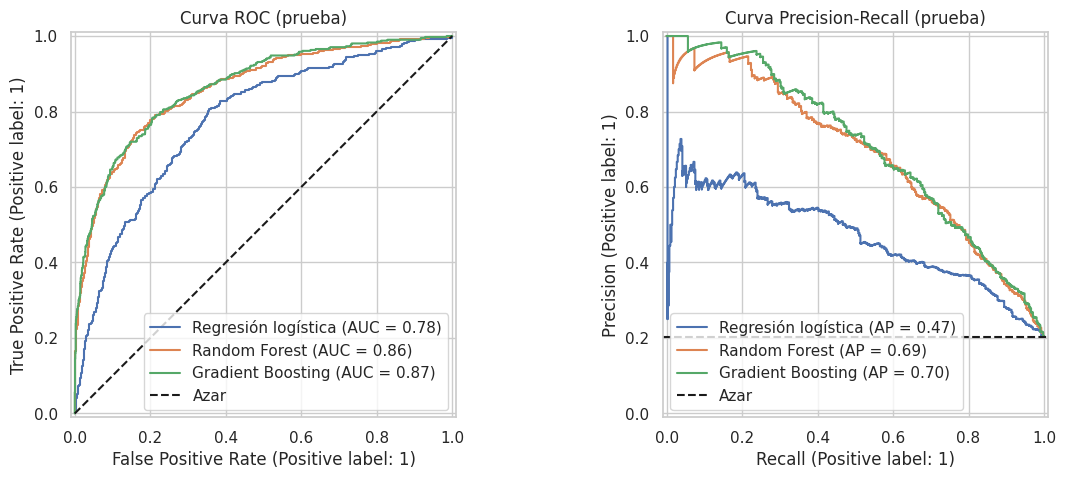

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n in busquedas:
    RocCurveDisplay.from_predictions(y_test, proba_test[n], name=n, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba_test[n], name=n, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="Azar"); axes[0].set_title("Curva ROC (prueba)")
axes[1].axhline(y_test.mean(), ls="--", color="k", label="Azar"); axes[1].set_title("Curva Precision-Recall (prueba)")
axes[0].legend(); axes[1].legend(); plt.show()

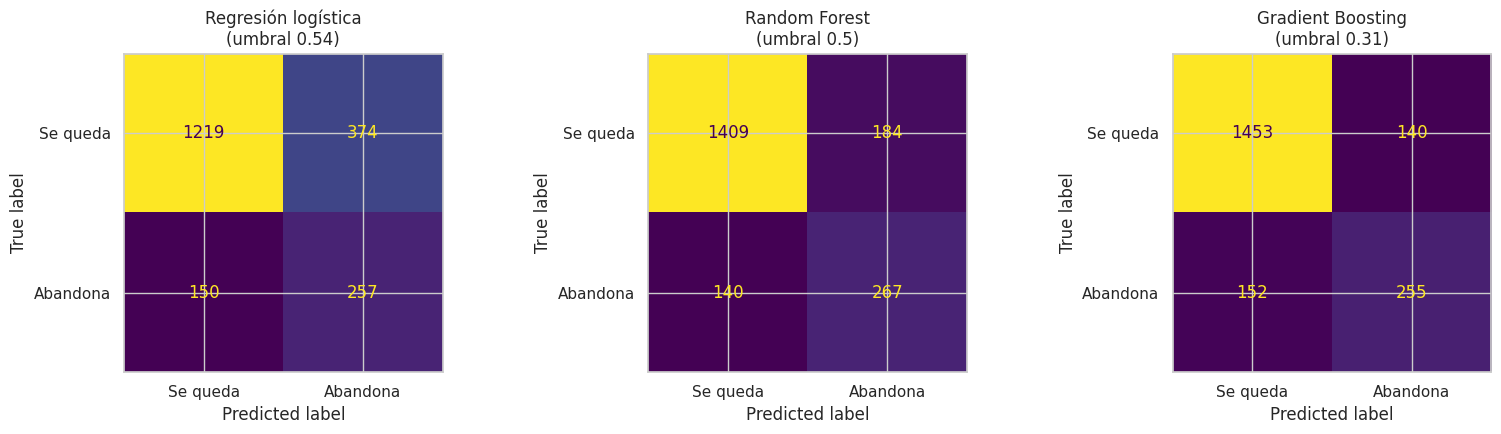

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, n in zip(axes, busquedas):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test[n] >= umbral_f1[n]).astype(int),
                                            display_labels=["Se queda", "Abandona"], ax=ax, colorbar=False)
    ax.set_title(f"{n}\n(umbral {umbral_f1[n]})")
plt.tight_layout(); plt.show()

### 3.3 ¿La diferencia entre modelos es real? Bootstrapping (clase 11)
Se remuestrea el conjunto de prueba 1.000 veces para obtener **intervalos de confianza del 95%** del ROC-AUC, y una **prueba A/B pareada** entre los dos mejores modelos.

In [20]:
rng = np.random.default_rng(SEMILLA)
B = 1000
y_arr = y_test.to_numpy()
auc_boot = {n: [] for n in busquedas}
for _ in range(B):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].sum() == 0:
        continue
    for n in busquedas:
        auc_boot[n].append(roc_auc_score(y_arr[idx], proba_test[n][idx]))

ic = pd.DataFrame({n: {"AUC prueba": roc_auc_score(y_arr, proba_test[n]),
                       "IC 95% inferior": np.percentile(v, 2.5),
                       "IC 95% superior": np.percentile(v, 97.5)} for n, v in auc_boot.items()}).T
print(ic)

# Prueba A/B pareada entre los dos mejores
top2 = ic.sort_values("AUC prueba", ascending=False).index[:2].tolist()
dif = np.array(auc_boot[top2[0]]) - np.array(auc_boot[top2[1]])
print(f"\nA/B: {top2[0]} − {top2[1]}: diferencia media de AUC = {dif.mean():.4f}, "
      f"IC 95% = [{np.percentile(dif, 2.5):.4f}, {np.percentile(dif, 97.5):.4f}]")
print("Si el intervalo NO contiene el 0, la diferencia es estadísticamente significativa.")

                     AUC prueba  IC 95% inferior  IC 95% superior
Regresión logística       0.778            0.750            0.803
Random Forest             0.861            0.838            0.880
Gradient Boosting         0.866            0.844            0.884

A/B: Gradient Boosting − Random Forest: diferencia media de AUC = 0.0052, IC 95% = [-0.0014, 0.0115]
Si el intervalo NO contiene el 0, la diferencia es estadísticamente significativa.


In [21]:
# >>> Modelo elegido: el de mayor AUC en prueba (verifíquenlo con la tabla y el A/B antes de escribir su justificación)
NOMBRE_FINAL = ic["AUC prueba"].idxmax()
modelo_final = busquedas[NOMBRE_FINAL].best_estimator_
print("Modelo elegido:", NOMBRE_FINAL)
print(classification_report(y_test, (proba_test[NOMBRE_FINAL] >= umbral_f1[NOMBRE_FINAL]).astype(int),
                            target_names=["Se queda", "Abandona"]))

Modelo elegido: Gradient Boosting
              precision    recall  f1-score   support

    Se queda       0.91      0.91      0.91      1593
    Abandona       0.65      0.63      0.64       407

    accuracy                           0.85      2000
   macro avg       0.78      0.77      0.77      2000
weighted avg       0.85      0.85      0.85      2000



**Análisis cuantitativo.**
- Recall representa cuántos clientes que realmente abandonan logra identificar el modelo. Precision indica cuántos de los clientes contactados realmente tenían intención de abandonar. Esta última métrica es importante porque contactar clientes que no pensaban irse representa un costo innecesario para el banco.
- La accuracy por sí sola puede generar conclusiones equivocadas: como aproximadamente el 80% de los clientes permanece, un modelo podría alcanzar esa exactitud prediciendo que nadie abandona, pero sería inútil para una campaña de retención.
- El modelo seleccionado es Gradient Boosting, con ROC-AUC de 0,866 e intervalo de confianza del 95% entre 0,844 y 0,884. Además, obtuvo el PR-AUC más alto (0,705), lo que demuestra un mejor desempeño en la identificación de la clase minoritaria: los clientes que abandonan.
- La prueba A/B entre Gradient Boosting y Random Forest muestra una diferencia de AUC de 0,0052, con intervalo de confianza entre -0,0014 y 0,0115. Como el intervalo incluye el cero, no existe evidencia estadística suficiente para afirmar que uno sea superior al otro. Se elige Gradient Boosting porque obtuvo el mayor AUC y PR-AUC, aunque la ventaja es pequeña.
- El umbral de decisión cambia considerablemente los resultados. Con 0,50, Gradient Boosting alcanza una precision de 0,771, pero un recall de apenas 0,464, por lo que deja escapar a más de la mitad de los clientes que abandonan. Al reducir el umbral a 0,31, el recall aumenta a 0,627 y la precision queda en 0,646. Para el banco resulta más conveniente este segundo escenario, porque permite identificar más clientes en riesgo sin perder completamente la eficiencia de las campañas.
- En términos de negocio, con el umbral de 0,31, el modelo identifica aproximadamente 63 de cada 100 clientes que realmente abandonan y, de cada 100 clientes contactados, alrededor de 65 efectivamente abandonan.
- Los buenos resultados se explican por la limpieza de los datos, el balanceo de clases en los modelos que lo requieren, la selección de hiperparámetros y la capacidad de los árboles para identificar relaciones complejas entre las variables.

**Oportunidades de mejora**:
- sería conveniente incorporar información sobre transacciones, movimientos de las cuentas, quejas y reclamos (PQRS), uso de canales digitales, historial de interacciones y comportamiento de los clientes en el tiempo. También sería importante entrenar y validar el modelo con información de clientes colombianos.

---
## 4. Análisis cualitativo – Interpretabilidad (20%)
Se usan técnicas de la clase 12: **globales** (coeficientes, importancia por permutación, PDP/ICE, SHAP resumen) y **locales** (SHAP por cliente, LIME).

In [22]:
# Datos ya imputados (formato que entra al modelo) para las herramientas de interpretación
preproc = modelo_final[:-1]          # todos los pasos del pipeline menos el modelo
estimador = modelo_final[-1]         # el modelo entrenado
Xtr_proc = pd.DataFrame(preproc.transform(X_train), columns=FEATURES, index=X_train.index)
Xte_proc = pd.DataFrame(preproc.transform(X_test), columns=FEATURES, index=X_test.index)

### 4.1 Global: coeficientes de la regresión logística (modelo intrínsecamente interpretable)

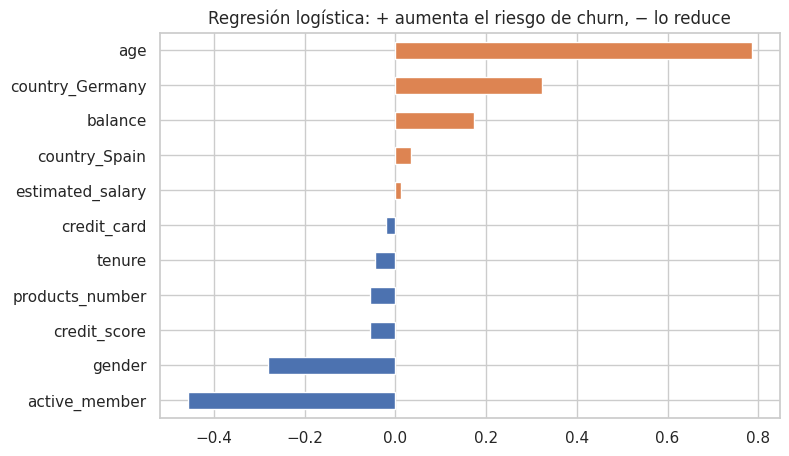

,coeficiente (estandarizado),odds ratio por +1 desv. estándar
active_member,-0.458,0.633
gender,-0.280,0.756
credit_score,-0.056,0.945
products_number,-0.056,0.945
tenure,-0.045,0.956
credit_card,-0.022,0.978
estimated_salary,0.012,1.012
country_Spain,0.034,1.035
balance,0.174,1.190
country_Germany,0.324,1.383


In [23]:
lr = busquedas["Regresión logística"].best_estimator_[-1]
coef = pd.DataFrame({"coeficiente (estandarizado)": lr.coef_[0],
                     "odds ratio por +1 desv. estándar": np.exp(lr.coef_[0])}, index=FEATURES)
coef = coef.sort_values("coeficiente (estandarizado)")
coef["coeficiente (estandarizado)"].plot(kind="barh", figsize=(8, 5), color=np.where(coef.iloc[:, 0] > 0, "#DD8452", "#4C72B0"))
plt.title("Regresión logística: + aumenta el riesgo de churn, − lo reduce"); plt.show()
coef

### 4.2 Global: importancia por permutación (modelo elegido)

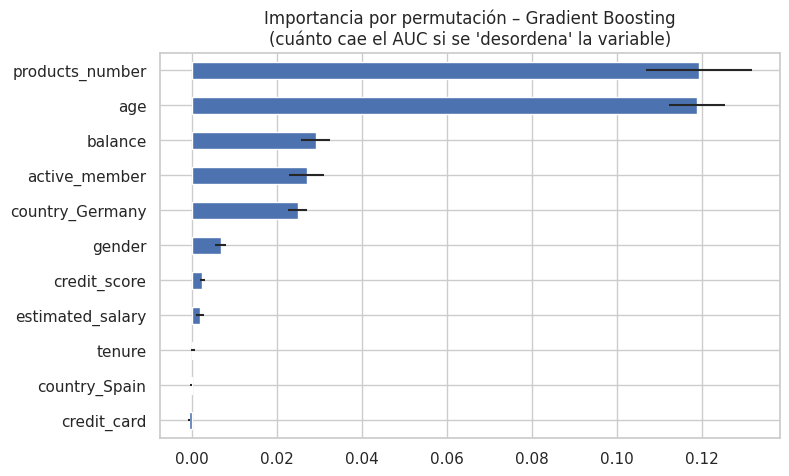

In [24]:
perm = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEMILLA, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(8, 5), xerr=perm.importances_std[np.argsort(perm.importances_mean)])
plt.title(f"Importancia por permutación – {NOMBRE_FINAL}\n(cuánto cae el AUC si se 'desordena' la variable)"); plt.show()

### 4.3 Global: dependencia parcial (PDP) y curvas ICE

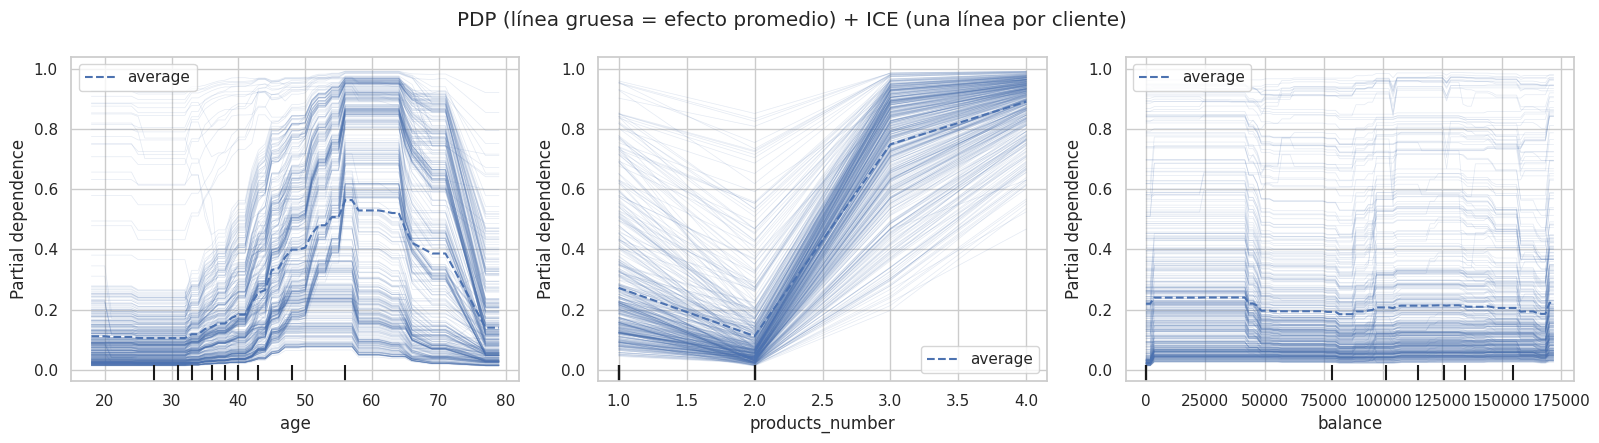

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
PartialDependenceDisplay.from_estimator(modelo_final, X_test.sample(500, random_state=SEMILLA),
                                        ["age", "products_number", "balance"], kind="both",
                                        ax=ax, ice_lines_kw={"alpha": 0.15}, random_state=SEMILLA)
plt.suptitle("PDP (línea gruesa = efecto promedio) + ICE (una línea por cliente)"); plt.tight_layout(); plt.show()

### 4.4 Global y local: valores SHAP

/tmp/ipykernel_1114/840396633.py:13: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, muestra, show=False)


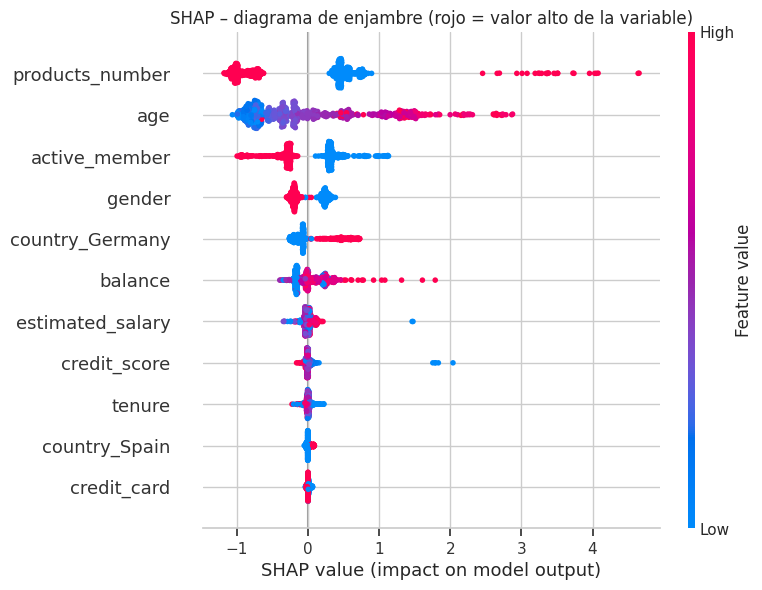

In [26]:
import shap
explainer = shap.TreeExplainer(estimador) if NOMBRE_FINAL != "Regresión logística" else shap.LinearExplainer(estimador, Xtr_proc)
muestra = Xte_proc.sample(800, random_state=SEMILLA)
sv = explainer.shap_values(muestra)
base = explainer.expected_value
# Según la versión de SHAP / el modelo, el resultado viene por clase: nos quedamos con la clase 1 (churn)
if isinstance(sv, list):
    sv, base = sv[1], base[1]
elif np.ndim(sv) == 3:
    sv, base = sv[:, :, 1], np.ravel(base)[1]
base = float(np.ravel(base)[-1])

shap.summary_plot(sv, muestra, show=False)
plt.title("SHAP – diagrama de enjambre (rojo = valor alto de la variable)"); plt.show()

**Predicciones individuales.** Se toman 3 clientes reales del conjunto de prueba: un verdadero positivo (abandonó y el modelo lo detectó), un falso positivo (el modelo dijo que se iba pero no) y un falso negativo (se fue y el modelo no lo vio).

,credit_score,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,country_Germany,country_Spain,churn,prob_churn
Verdadero positivo,376.000,0.000,29.000,4.000,"115,046.740",4.000,1.000,0.000,"119,346.880",1.000,0.000,1,0.991
Falso positivo,506.000,0.000,59.000,3.000,"190,353.080",1.000,1.000,0.000,"78,365.750",1.000,0.000,0,0.951
Falso negativo,726.000,1.000,29.000,7.000,0.000,2.000,1.000,1.000,"91,844.140",0.000,0.000,1,0.015


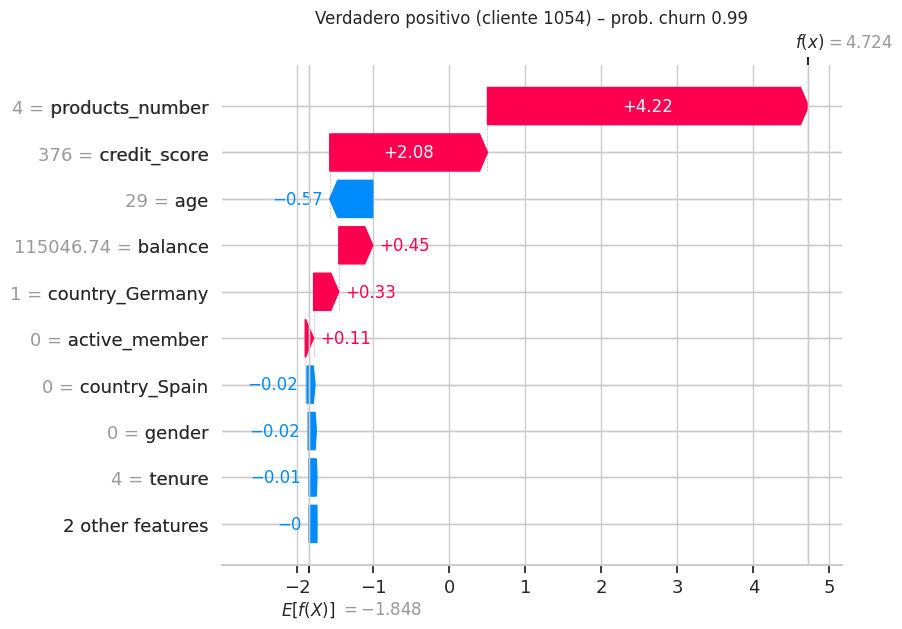

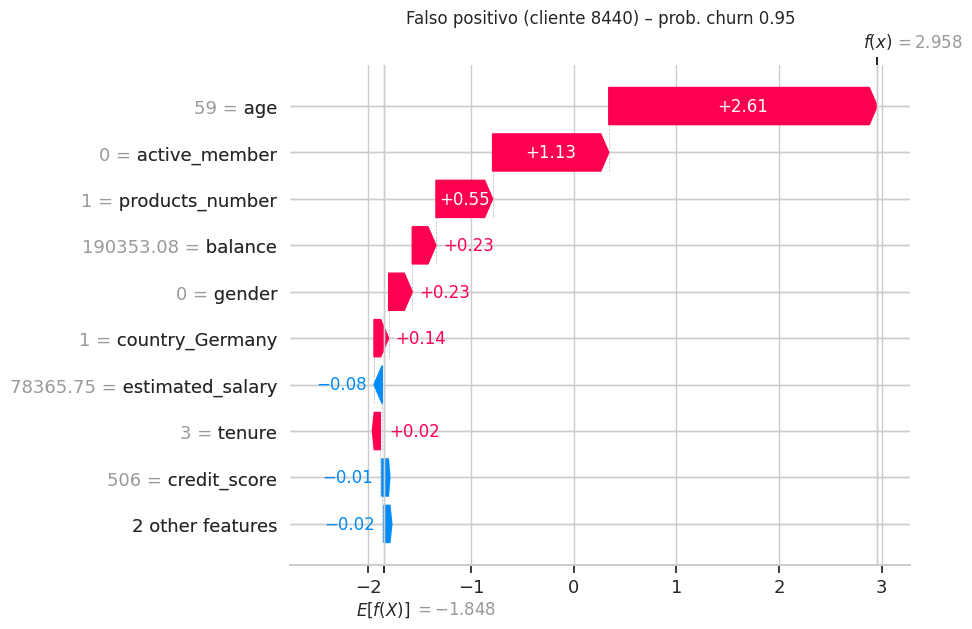

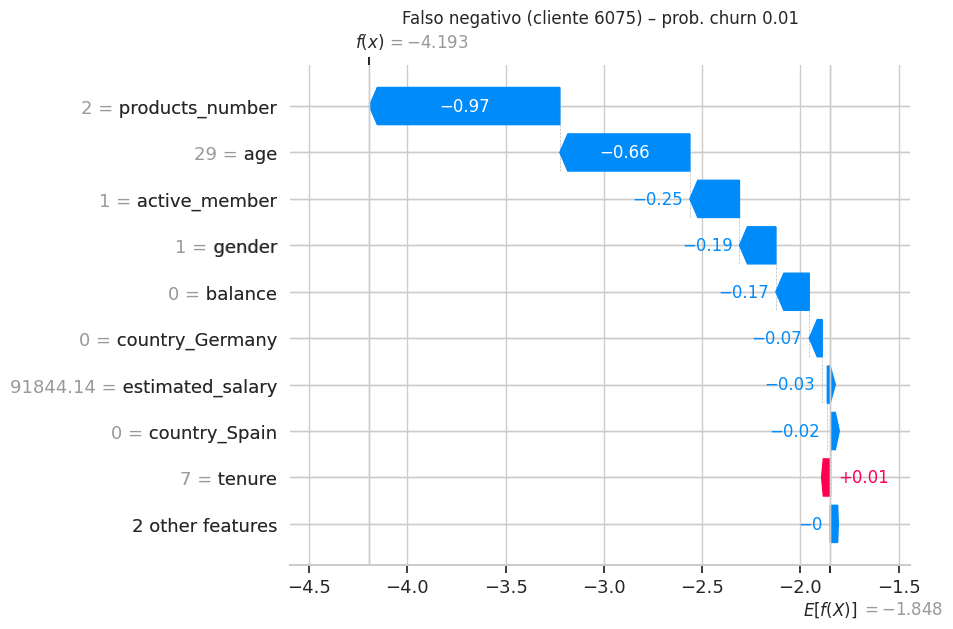

In [27]:
u = umbral_f1[NOMBRE_FINAL]
p_final = pd.Series(proba_test[NOMBRE_FINAL], index=X_test.index)
pred_final = (p_final >= u).astype(int)
casos = {
    "Verdadero positivo": p_final[(pred_final == 1) & (y_test == 1)].idxmax(),
    "Falso positivo":     p_final[(pred_final == 1) & (y_test == 0)].idxmax(),
    "Falso negativo":     p_final[(pred_final == 0) & (y_test == 1)].idxmin(),
}
display(pd.concat([X_test.loc[list(casos.values())], y_test.loc[list(casos.values())],
                   p_final.loc[list(casos.values())].rename("prob_churn")], axis=1)
        .set_axis(list(casos.keys())))

sv_casos = explainer.shap_values(Xte_proc.loc[list(casos.values())])
if isinstance(sv_casos, list):
    sv_casos = sv_casos[1]
elif np.ndim(sv_casos) == 3:
    sv_casos = sv_casos[:, :, 1]
for i, (etiqueta, idx) in enumerate(casos.items()):
    exp = shap.Explanation(values=sv_casos[i], base_values=base,
                           data=X_test.loc[idx].values, feature_names=FEATURES)
    shap.plots.waterfall(exp, show=False)
    plt.title(f"{etiqueta} (cliente {idx}) – prob. churn {p_final[idx]:.2f}"); plt.show()

### 4.5 Local: LIME (sustituto local)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(


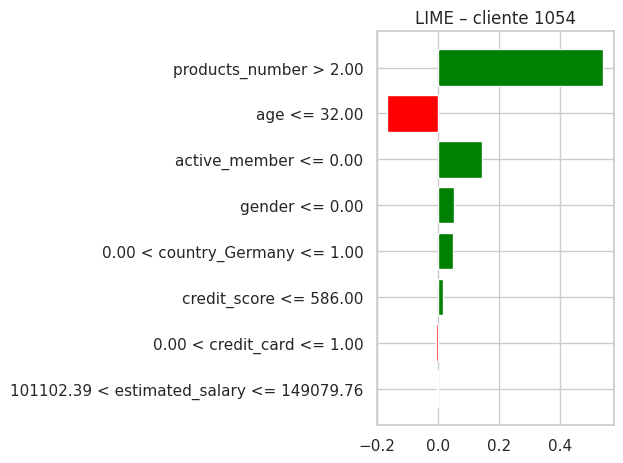

[('products_number > 2.00', 0.5415447748431227),
 ('age <= 32.00', -0.16689608836582376),
 ('active_member <= 0.00', 0.14285639474365286),
 ('gender <= 0.00', 0.05024626647521689),
 ('0.00 < country_Germany <= 1.00', 0.04791969373973386),
 ('credit_score <= 586.00', 0.016891243131104593),
 ('0.00 < credit_card <= 1.00', -0.008052711934771115),
 ('101102.39 < estimated_salary <= 149079.76', -0.005403751286790402)]

In [28]:
from lime.lime_tabular import LimeTabularExplainer
lime_exp = LimeTabularExplainer(Xtr_proc.values, feature_names=FEATURES,
                                class_names=["Se queda", "Abandona"], mode="classification",
                                discretize_continuous=True, random_state=SEMILLA)
predecir = lambda arr: estimador.predict_proba(pd.DataFrame(arr, columns=FEATURES))
idx = casos["Verdadero positivo"]
exp_lime = lime_exp.explain_instance(Xte_proc.loc[idx].values, predecir, num_features=8)
exp_lime.as_pyplot_figure(); plt.title(f"LIME – cliente {idx}"); plt.tight_layout(); plt.show()
exp_lime.as_list()

**Interpretación del modelo.**

**A nivel global**:
- las variables más importantes para predecir el abandono son el número de productos y la edad. También tienen influencia el saldo, ser miembro activo, pertenecer a Alemania y el género. La importancia por permutación y SHAP coinciden especialmente en destacar el número de productos y la edad..

**A nivel local**:
- Según SHAP, tener 3 o 4 productos, ser mayor, estar inactivo, ser mujer y pertenecer a Alemania aumentan la probabilidad de abandono. Esto permite identificar características que el banco puede utilizar para diseñar estrategias de retención.
- La regresión logística asigna al número de productos un coeficiente de apenas -0,056, lo que indica que prácticamente no identifica su efecto real. Esto ocurre porque la relación no es lineal: el riesgo disminuye con 2 productos, pero aumenta considerablemente con 3 y 4. Los modelos de árboles logran capturar este comportamiento y por eso obtienen mejores resultados.
- La gráfica PDP de edad muestra que el riesgo de abandono se mantiene relativamente bajo hasta los 35-40 años, aumenta considerablemente entre los 45 y 65 años y alcanza su punto más alto aproximadamente entre los 56 y 62 años. Después disminuye. Una posible explicación es que los clientes de mediana edad pueden tener mayores expectativas sobre los servicios financieros y ser más sensibles a problemas de atención, costos o beneficios.
- Verdadero positivo: corresponde a un cliente de 29 años, con 4 productos, inactivo y ubicado en Alemania, al que el modelo asignó una probabilidad de abandono de 99,1%. La variable que más influyó fue tener 4 productos, seguida del puntaje crediticio bajo. En este caso, el modelo identificó correctamente a un cliente que efectivamente abandonó.
- Falso positivo: corresponde a una mujer de 59 años, inactiva, con un producto y ubicada en Alemania. El modelo calculó una probabilidad de abandono del 95,1%, pero la cliente permaneció en el banco. Aunque presentaba varias características asociadas al riesgo, el modelo no conoce factores como su satisfacción, relación con el asesor, beneficios recibidos o motivos personales para continuar.
- Falso negativo: corresponde a un hombre de 29 años, activo y con 2 productos, al que el modelo asignó apenas un 1,5% de probabilidad de abandono, aunque efectivamente se fue. Esto puede explicarse por situaciones que no están representadas en los datos, como una oferta más atractiva de otro banco, una mala experiencia reciente o necesidades financieras particulares.
- LIME confirma los resultados de SHAP para el verdadero positivo: tener más de 2 productos es el factor que más incrementa la predicción de abandono, seguido de estar inactivo. Esto demuestra que ambas herramientas ofrecen explicaciones similares para ese cliente.
- Existe un posible riesgo de sesgo porque el género y el país influyen en las predicciones. El banco debe vigilar que estas variables no generen decisiones discriminatorias y utilizarlas únicamente como señales para analizar patrones de abandono, garantizando que las acciones comerciales sean justas para todos los clientes.

---
## 5. Generación de valor (20%)
### 5.1 Supuestos (TODOS deben quedar explícitos y con fuente)
Todos los valores en COP. Tasa de cambio usada: TRM de COP 3.228 por dólar (6-nov-2026).

| Parámetro | Valor | Fuente / justificación |
|---|---|---|
| Clientes del banco (N) | 20.000 | Enunciado del taller |
| Tasa de churn anual del banco (p) | 15% | Enunciado (businessweekly.co.bw) |
| Ingreso anual por cliente activo (V) | COP 700.000 (rango 500k–900k) | Enunciado – reporte 6-K de Nu Holdings ante la SEC |
| Efectividad de la campaña (r) | 30% de los que se iban se quedan | Enunciado |
| Costo por cliente contactado (C) | **COP 38.000** = contacto COP 13.000 + incentivo COP 25.000 | **Contacto:** agente de call center en Colombia USD 12–20/hora con todo incluido (FusionCX, ago-2026). Se toma USD 16/h × TRM ≈ COP 51.650/h y unos 4 contactos efectivos por hora (≈15 min, con reintentos), lo que da ≈ COP 13.000. **Incentivo:** exonerar un mes de cuota de manejo de la tarjeta, que en Colombia va de COP 14.900 a 40.890 al mes (La República, 2022) y llega a COP 47.500 en tarjetas premium (La FM, 2025). Se toma COP 25.000. Según el enunciado, se paga por todo cliente contactado. |
| Costo de implementación (único) | **COP 26,2 millones** = 2 científicos de datos × 1 mes (320 h) × COP 82.000/h | Salario mediano de un científico de datos en Colombia: COP 157,9 millones/año (Levels.fyi, 2026) ÷ 1.920 h/año ≈ COP 82.000/h. (La clase 11 usó COP 28.700/h, que sería un escenario más barato.) |
| Costo de operación (anual) | **COP 19,1 millones/año** = nube COP 3,3 M + mantenimiento COP 15,8 M | Nube: instancia ml.m5.large de AWS SageMaker a USD 0,115/h × 8.760 h × TRM ≈ COP 3,3 M (Cloudchipr, 2024). Mantenimiento: 10% del tiempo de un científico de datos para monitoreo y reentrenamiento ≈ COP 15,8 M. |
| Horizonte | 1 año de ingresos del cliente retenido | Conservador (no se usa valor de vida del cliente) |

### 5.2 Matriz de costo/beneficio (línea base = no usar el modelo)
|  | Realmente abandona (p) | Realmente se queda (n) |
|---|---|---|
| **Predicho abandona (contactado)** | b(P,p) = r·V − C | c(P,n) = −C |
| **Predicho se queda (no contactado)** | c(N,p) = 0 | b(N,n) = 0 |

**Fórmula de Provost** (clase 11), usando la tasa de churn del banco (15%) en lugar de la del dataset (20%):

$$\hat{a} = p\,[\,TPR\cdot(rV - C) + (1-TPR)\cdot 0\,] + (1-p)\,[\,(1-FPR)\cdot 0 + FPR\cdot(-C)\,]$$

In [29]:
# ======= PARÁMETROS (cámbienlos aquí y todo se recalcula) =======
N_CLIENTES = 20_000
P_CHURN = 0.15              # tasa de churn del banco
V_INGRESO = 700_000         # COP ingreso anual por cliente activo
R_EFECTIVIDAD = 0.30        # % de los que se iban que la campaña retiene
TRM = 3_228                 # COP por USD (6-nov-2026)

# Costo por cliente contactado = llamada de call center + incentivo de retención
COSTO_LLAMADA = 16 * TRM / 4          # USD 16/hora de agente, 4 contactos por hora  -> ~COP 13.000
INCENTIVO = 25_000                    # 1 mes de cuota de manejo exonerada
C_CONTACTO = round(COSTO_LLAMADA + INCENTIVO, -3)

# Costo de implementación (una sola vez)
TARIFA_HORA_CD = 82_000     # COP/hora científico de datos (Levels.fyi: COP 157,9 M/año ÷ 1.920 h)
HORAS_PROYECTO = 2 * 160    # 2 científicos de datos x 1 mes
COSTO_IMPL = TARIFA_HORA_CD * HORAS_PROYECTO

# Costo de operación (cada año)
NUBE_ANUAL = 0.115 * 8_760 * TRM                  # AWS SageMaker ml.m5.large encendida todo el año
MANTENIMIENTO_ANUAL = 0.10 * 157_947_359          # 10% del tiempo de un científico de datos
COSTO_OPER_ANUAL = NUBE_ANUAL + MANTENIMIENTO_ANUAL

print(f"Costo por cliente contactado:  COP {C_CONTACTO:,.0f}")
print(f"Costo de implementación:       COP {COSTO_IMPL:,.0f}")
print(f"Costo de operación anual:      COP {COSTO_OPER_ANUAL:,.0f}")

def ganancia_por_cliente(tpr, fpr, p=P_CHURN, V=V_INGRESO, r=R_EFECTIVIDAD, C=C_CONTACTO):
    # Fórmula de Provost: ganancia esperada por cliente frente a no usar el modelo
    return p * tpr * (r * V - C) + (1 - p) * fpr * (-C)

def tasas(y_true, proba, u):
    tn, fp, fn, tp = confusion_matrix(y_true, (proba >= u).astype(int)).ravel()
    return tp / (tp + fn), fp / (fp + tn)

Costo por cliente contactado:  COP 38,000
Costo de implementación:       COP 26,240,000
Costo de operación anual:      COP 19,046,623


### 5.3 Umbral que maximiza la ganancia
El umbral se elige con las predicciones de validación cruzada (entrenamiento) y luego se reporta la ganancia en prueba.

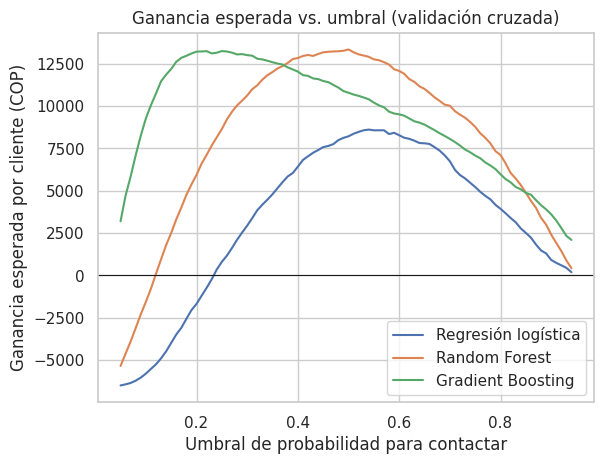

,Umbral óptimo,TPR (recall),FPR (fall-out),Ganancia por cliente (COP),Ganancia anual banco (COP)
Modelo,,,,,
Regresión logística,0.540,0.631,0.235,"8,708.099","174,161,970.908"
Random Forest,0.500,0.656,0.116,"13,194.485","263,889,695.551"
Gradient Boosting,0.250,0.683,0.124,"13,628.191","272,563,827.310"


In [30]:
curvas = {}
for n in busquedas:
    curvas[n] = [ganancia_por_cliente(*tasas(y_train, proba_cv[n], u)) for u in umbrales]
    plt.plot(umbrales, curvas[n], label=n)
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("Umbral de probabilidad para contactar"); plt.ylabel("Ganancia esperada por cliente (COP)")
plt.title("Ganancia esperada vs. umbral (validación cruzada)"); plt.legend(); plt.show()

umbral_valor = {n: umbrales[int(np.argmax(c))] for n, c in curvas.items()}
filas = []
for n in busquedas:
    tpr, fpr = tasas(y_test, proba_test[n], umbral_valor[n])
    g = ganancia_por_cliente(tpr, fpr)
    filas.append({"Modelo": n, "Umbral óptimo": umbral_valor[n], "TPR (recall)": tpr, "FPR (fall-out)": fpr,
                  "Ganancia por cliente (COP)": g, "Ganancia anual banco (COP)": g * N_CLIENTES})
valor = pd.DataFrame(filas).set_index("Modelo")
valor

### 5.4 Ganancia total, comparación con alternativas y punto de equilibrio

In [31]:
tpr, fpr = tasas(y_test, proba_test[NOMBRE_FINAL], umbral_valor[NOMBRE_FINAL])
g_cliente = ganancia_por_cliente(tpr, fpr)
g_anual = g_cliente * N_CLIENTES
contactados = N_CLIENTES * (P_CHURN * tpr + (1 - P_CHURN) * fpr)
retenidos = N_CLIENTES * P_CHURN * tpr * R_EFECTIVIDAD

# Alternativas sin modelo
g_todos = ganancia_por_cliente(1, 1) * N_CLIENTES     # contactar a todos
g_nadie = 0                                           # no hacer nada (línea base)

print(f"Modelo: {NOMBRE_FINAL}, umbral {umbral_valor[NOMBRE_FINAL]}")
print(f"  Clientes contactados al año:   {contactados:,.0f}")
print(f"  Clientes retenidos al año:     {retenidos:,.0f}")
print(f"  Ganancia por cliente:          COP {g_cliente:,.0f}")
print(f"  Ganancia anual (20.000 cl.):   COP {g_anual:,.0f}")
print(f"  Alternativa 'contactar a todos': COP {g_todos:,.0f}")
print(f"  Alternativa 'no hacer nada':     COP {g_nadie:,.0f}")

g_neta_anual = g_anual - COSTO_OPER_ANUAL
roi_1 = (g_neta_anual - COSTO_IMPL) / COSTO_IMPL
print(f"  Ganancia neta anual (menos operación): COP {g_neta_anual:,.0f}")
print(f"  ROI del primer año: {roi_1:.0%}")

meses_be = COSTO_IMPL / (g_neta_anual / 12) if g_neta_anual > 0 else np.inf
clientes_be = (COSTO_IMPL + COSTO_OPER_ANUAL) / g_cliente if g_cliente > 0 else np.inf
print(f"\nPUNTO DE EQUILIBRIO:")
print(f"  En tiempo: {meses_be:.1f} meses de operación")
print(f"  En tamaño: para pagar implementación + 1 año de operación se necesita un banco de al menos {clientes_be:,.0f} clientes")
print(f"  En calidad del modelo: contactar es rentable si la PRECISIÓN > C/(r·V) = {C_CONTACTO/(R_EFECTIVIDAD*V_INGRESO):.1%}")

Modelo: Gradient Boosting, umbral 0.25
  Clientes contactados al año:   4,151
  Clientes retenidos al año:     615
  Ganancia por cliente:          COP 13,628
  Ganancia anual (20.000 cl.):   COP 272,563,827
  Alternativa 'contactar a todos': COP -130,000,000
  Alternativa 'no hacer nada':     COP 0
  Ganancia neta anual (menos operación): COP 253,517,204
  ROI del primer año: 866%

PUNTO DE EQUILIBRIO:
  En tiempo: 1.2 meses de operación
  En tamaño: para pagar implementación + 1 año de operación se necesita un banco de al menos 3,323 clientes
  En calidad del modelo: contactar es rentable si la PRECISIÓN > C/(r·V) = 18.1%


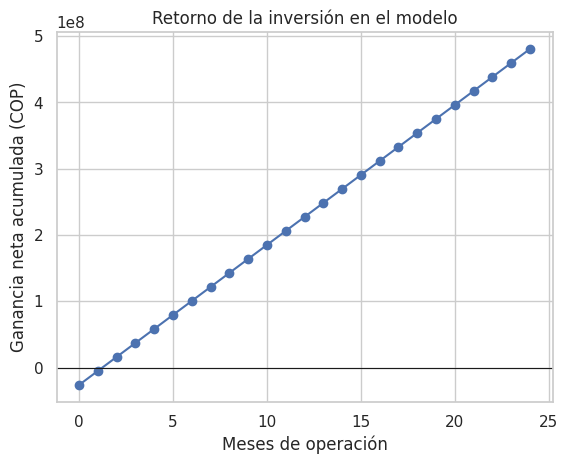

In [32]:
# Ganancia acumulada vs. costo: gráfico del break-even
meses = np.arange(0, 25)
plt.plot(meses, g_neta_anual / 12 * meses - COSTO_IMPL, marker="o")
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("Meses de operación"); plt.ylabel("Ganancia neta acumulada (COP)")
plt.title("Retorno de la inversión en el modelo"); plt.show()

### 5.5 Análisis de sensibilidad (estimación paramétrica)

In [33]:
# ¿Cómo cambia la ganancia anual si cambian el ingreso por cliente y el costo de contacto?
sens = pd.DataFrame(index=[f"V={v:,}" for v in [500_000, 700_000, 900_000]],
                    columns=[f"C={c:,}" for c in [20_000, 40_000, 60_000, 100_000]], dtype=float)
for v in [500_000, 700_000, 900_000]:
    for c in [20_000, 40_000, 60_000, 100_000]:
        # se re-optimiza el umbral para cada escenario
        g = max(ganancia_por_cliente(*tasas(y_train, proba_cv[NOMBRE_FINAL], u), V=v, C=c) for u in umbrales)
        u_opt = umbrales[int(np.argmax([ganancia_por_cliente(*tasas(y_train, proba_cv[NOMBRE_FINAL], u), V=v, C=c) for u in umbrales]))]
        sens.loc[f"V={v:,}", f"C={c:,}"] = ganancia_por_cliente(*tasas(y_test, proba_test[NOMBRE_FINAL], u_opt), V=v, C=c) * N_CLIENTES / 1e6
print("Ganancia anual del banco en MILLONES de COP")
sens.round(1)

Ganancia anual del banco en MILLONES de COP


,"C=20,000","C=40,000","C=60,000","C=100,000"
"V=500,000",232.200,147.000,88.400,23.000
"V=700,000",374.300,264.300,189.200,91.100
"V=900,000",528.200,389.000,305.100,176.400


In [34]:
# Sensibilidad a la efectividad de la campaña (r)
for r in [0.10, 0.20, 0.30, 0.40]:
    g = ganancia_por_cliente(tpr, fpr, r=r) * N_CLIENTES
    print(f"Efectividad {r:.0%}: ganancia anual COP {g/1e6:,.1f} millones")

Efectividad 10%: ganancia anual COP -14.3 millones
Efectividad 20%: ganancia anual COP 129.1 millones
Efectividad 30%: ganancia anual COP 272.6 millones
Efectividad 40%: ganancia anual COP 416.0 millones


**Generación de valor**
- Con un umbral de decisión de 0,25, el banco contactaría aproximadamente 4.151 clientes al año y lograría retener cerca de 615 clientes, suponiendo una efectividad de campaña del 30%.
- La ganancia esperada es de COP 13.628 por cliente, lo que representa aproximadamente COP 272,6 millones anuales para un banco con 20.000 clientes.
- Después de descontar los costos operativos anuales de aproximadamente COP 19 millones, la ganancia neta sería de COP 253,5 millones. Considerando una inversión inicial de COP 26,24 millones, el ROI del primer año sería del 866%.
- El punto de equilibrio se alcanza aproximadamente en 1,2 meses, lo que significa que el proyecto recuperaría rápidamente la inversión inicial bajo los supuestos establecidos.
- La alternativa de contactar a todos los clientes generaría una pérdida estimada de COP 130 millones. Esto demuestra que el valor del modelo está en identificar a quién contactar y evitar gastar recursos en clientes que probablemente permanecerían en el banco sin recibir una campaña.
- La campaña es rentable cuando la precision supera el 18,1%. El modelo supera ese mínimo en los escenarios evaluados, lo que indica que la estrategia tiene margen para absorber errores de clasificación y costos de contacto.
- En el análisis de sensibilidad, incluso en el escenario más desfavorable de la tabla, con ingresos de COP 500.000 por cliente y costos de contacto de COP 100.000, se mantiene una ganancia de COP 23 millones anuales.
- La principal debilidad es la efectividad de la campaña: si solamente se logra retener al 10% de los clientes identificados, el resultado sería una pérdida de aproximadamente COP 14,3 millones. Por tanto, el éxito no depende únicamente de predecir correctamente el abandono, sino también de ofrecer incentivos y acciones que realmente convenzan al cliente de quedarse.

**limitaciones.**
- Los datos utilizados corresponden a clientes de países europeos y no de Colombia. Por lo tanto, los patrones de comportamiento pueden ser diferentes debido a las condiciones económicas, los hábitos financieros, la competencia bancaria y las características del mercado colombiano. Se necesita validar el modelo con información local antes de implementarlo.
- La efectividad de la campaña del 30%, los cuatro contactos por hora y el 10% de mantenimiento anual son supuestos utilizados para los cálculos financieros, no resultados de una campaña real.
- Algunas fuentes utilizadas para estimar los costos corresponden a periodos anteriores, como las cuotas de manejo de 2022 y los precios de AWS de 2024, por lo que deben actualizarse para una implementación real.
- El modelo utiliza principalmente características estáticas de los clientes y no incorpora su comportamiento a lo largo del tiempo. Por esta razón, debe monitorearse periódicamente y reentrenarse con información actualizada.
- El análisis financiero considera únicamente un horizonte de un año, por lo que puede subestimar el valor real de retener a un cliente, especialmente si continúa utilizando los productos y servicios del banco durante varios años.

---
## 6. Insights y recomendación (10%)
1. Perfil del cliente en riesgo: el análisis identifica que las variables más relevantes para predecir el abandono son el número de productos y la edad. El perfil de mayor riesgo se concentra especialmente en clientes con 3 o 4 productos, personas mayores de 45 años (con mayor riesgo entre los 56 y 62 años) y clientes inactivos. También se observa una mayor propensión al abandono en mujeres y clientes de Alemania. Estas características permiten identificar segmentos prioritarios para las estrategias de retención.

2. Calidad del modelo: Gradient Boosting presenta un buen desempeño predictivo, con un ROC-AUC de 0,866. Utilizando un umbral de 0,31, identifica aproximadamente 63 de cada 100 clientes que abandonan y, de cada 100 clientes contactados, alrededor de 65 realmente abandonan. Esto permite al banco anticiparse a una parte importante de las deserciones y orientar mejor sus recursos comerciales.

3. Valor económico: para una entidad con 20.000 clientes, se estima una ganancia anual de COP 272,6 millones antes de costos operativos y de COP 253,5 millones después de estos costos. La inversión inicial se recuperaría en aproximadamente 1,2 meses, con un ROI estimado del 866% durante el primer año, bajo los supuestos establecidos en el ejercicio.

4. Recomendación: recomendamos implementar Gradient Boosting mediante un piloto controlado, utilizando inicialmente el umbral de 0,25, que es el que maximiza la ganancia económica estimada. Las campañas deben adaptarse a las características de cada segmento:
- Clientes con un producto: identificar oportunidades para ofrecer productos complementarios que respondan a sus necesidades y fortalezcan su vinculación con el banco.
- Clientes con 3 o 4 productos: revisar su satisfacción, identificar posibles dificultades con los servicios contratados y ofrecer acompañamiento personalizado.
- Clientes inactivos: desarrollar campañas de reactivación, incentivos por uso de productos y seguimiento comercial.
- Clientes entre 45 y 65 años: ofrecer asesoría financiera personalizada, atención preferencial y soluciones acordes con sus necesidades.
- Clientes identificados con alto riesgo: realizar contactos preventivos para conocer sus motivos de insatisfacción y ofrecer alternativas de retención.

Antes de extender la solución a toda la entidad, proponemos realizar una prueba A/B: un grupo de clientes identificados por el modelo recibiría las campañas de retención, mientras que otro grupo comparable serviría como control. Esto permitirá medir la efectividad real de las campañas, validar el supuesto de retención del 30% y comprobar si los beneficios económicos proyectados se alcanzan en la práctica.

## 7. Declaración de uso de IA generativa (5%)
✍️ Modelo(s) usados, porcentaje aproximado de ayuda por sección, y anexar los prompts (p. ej. en `prompts_IA.md` en el repositorio).